In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import sys

sys.path.append(
    "/content/drive/MyDrive/pizza_rl_pj"
)

from pizza_env import PizzaKitchenEnv

print("PizzaKitchenEnv import 성공!")

PizzaKitchenEnv import 성공!


In [ ]:
import csv
from pathlib import Path

import numpy as np
import pandas as pd

from pizza_env import PizzaKitchenEnv


# ---------------------------------------------------------
# 1. Greedy Action
# ---------------------------------------------------------
def greedy_action(q_values, rng):
    # Q값이 동일한 행동이 있다면 무작위 선택
    return int(rng.choice(np.flatnonzero(q_values == q_values.max())))


# ---------------------------------------------------------
# 2. Stage 2 Q-Learning 학습
# ---------------------------------------------------------
def train_stage2(
    episodes=50000,
    seed=42,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_end=0.05,
    epsilon_decay=0.9999
):
    """
    Stage 2 Q-Learning
    - 주문 수: 4개
    - 제한 시간: 6~16
    - Observation: Discrete
    - Q-table: Dictionary 기반 Sparse Q-table
    """

    env = PizzaKitchenEnv(
        n_orders=4,
        min_deadline=6,
        max_deadline=16,
        observation_mode="discrete"
    )

    rng = np.random.default_rng(seed)

    # 방문한 상태만 저장하는 Sparse Q-table
    # key: state ID
    # value: 해당 상태의 행동별 Q-value
    q = {}

    history = []

    print("--- Stage 2 Q-Learning 학습 시작 ---")
    print(f"상태 공간 크기: {env.observation_space.n:,}")
    print(f"행동 수: {env.action_space.n}")
    print(f"학습 에피소드: {episodes:,}")

    for episode in range(episodes):

        state, _ = env.reset(seed=seed + episode)
        state = int(state)

        done = False

        # Epsilon Decay
        epsilon = max(
            epsilon_end,
            epsilon_start * (epsilon_decay ** episode)
        )

        while not done:

            # 현재 상태의 Q값 생성
            if state not in q:
                q[state] = np.zeros(
                    env.action_space.n,
                    dtype=np.float32
                )

            # Epsilon-greedy Action Selection
            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = greedy_action(q[state], rng)

            # Environment Step
            next_state, reward, terminated, truncated, info = env.step(action)

            next_state = int(next_state)
            done = terminated or truncated

            # 다음 상태의 Q값 조회
            # 아직 방문하지 않은 상태는 모든 Q값을 0으로 간주
            next_q = q.get(
                next_state,
                np.zeros(env.action_space.n, dtype=np.float32)
            )

            # Bellman Equation
            target = (
                reward
                if done
                else reward + gamma * np.max(next_q)
            )

            # Q-value Update
            q[state][action] += alpha * (
                target - q[state][action]
            )

            state = next_state

        # Episode History
        history.append({
            "episode": episode + 1,
            "reward": info["episode_return"],
            "served": info["served"],
            "expired": info["expired"],
            "wrong_serves": info["wrong_serves"],
            "steps": info["steps"],
            "epsilon": epsilon
        })

        # 10,000 Episode마다 학습 진행 상황 출력
        if (episode + 1) % 10000 == 0:

            recent = history[-1000:]

            recent_reward = np.mean(
                [h["reward"] for h in recent]
            )

            recent_served = np.mean(
                [h["served"] for h in recent]
            )

            print(
                f"Episode {episode + 1:5d}/{episodes} | "
                f"Avg Reward: {recent_reward:7.2f} | "
                f"Avg Served: {recent_served:.2f} | "
                f"Visited States: {len(q):,}"
            )

    env.close()

    print("\n--- Stage 2 학습 완료 ---")
    print(f"방문한 상태 수: {len(q):,}")

    return q, history


# ---------------------------------------------------------
# 3. Stage 2 모델 평가
# ---------------------------------------------------------
def evaluate_stage2(q, episodes=1000, seed=200000):

    env = PizzaKitchenEnv(
        n_orders=4,
        min_deadline=6,
        max_deadline=16,
        observation_mode="discrete"
    )

    rng = np.random.default_rng(seed)

    results = []

    for episode in range(episodes):

        state, _ = env.reset(seed=seed + episode)
        state = int(state)

        done = False

        while not done:

            # 방문하지 않은 상태는 Q값을 0으로 처리
            q_values = q.get(
                state,
                np.zeros(env.action_space.n, dtype=np.float32)
            )

            # 학습된 Greedy Policy로 행동 선택
            action = greedy_action(q_values, rng)

            state, _, terminated, truncated, info = env.step(action)

            state = int(state)
            done = terminated or truncated

        results.append(info)

    env.close()

    # Evaluation Metrics
    total_orders = episodes * 4
    total_served = sum(r["served"] for r in results)

    eval_summary = {
        "Evaluation Metric": [
            "Total Evaluation Episodes",
            "Average Reward (Return)",
            "Order Completion Rate (%)",
            "Average Served Orders (Max 4)",
            "Average Expired Orders",
            "Average Wrong Serves",
            "Average Steps per Episode"
        ],

        "Value": [
            f"{episodes:,}",
            f"{np.mean([r['episode_return'] for r in results]):.2f}",
            f"{(total_served / total_orders) * 100:.2f}%",
            f"{np.mean([r['served'] for r in results]):.2f} / 4.0",
            f"{np.mean([r['expired'] for r in results]):.2f}",
            f"{np.mean([r['wrong_serves'] for r in results]):.2f}",
            f"{np.mean([r['steps'] for r in results]):.2f}"
        ]
    }

    return pd.DataFrame(eval_summary)


# ---------------------------------------------------------
# 4. 결과 저장 경로
# ---------------------------------------------------------
output = Path(
    "/content/drive/MyDrive/pizza_rl_pj/results_stage2"
)

output.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------
# 5. Q-Learning 학습 실행
# ---------------------------------------------------------
q_stage2, history_stage2 = train_stage2(
    episodes=50000,
    seed=42
)


# ---------------------------------------------------------
# 6. Sparse Q-table 저장
# ---------------------------------------------------------
# Dictionary를 NumPy 배열로 변환
states = np.array(
    list(q_stage2.keys()),
    dtype=np.int64
)

values = np.stack(
    list(q_stage2.values())
)

# 압축하여 저장
np.savez_compressed(
    output / "q_table_stage2.npz",
    states=states,
    values=values
)

print(f"\nQ-table 저장 완료: {len(states):,} states")


# ---------------------------------------------------------
# 7. 학습 History CSV 저장
# ---------------------------------------------------------
history_df = pd.DataFrame(history_stage2)

history_df.to_csv(
    output / "q_learning_history_stage2.csv",
    index=False
)


# ---------------------------------------------------------
# 8. 모델 성능 평가
# ---------------------------------------------------------
df_performance = evaluate_stage2(
    q_stage2,
    episodes=1000,
    seed=200000
)


# ---------------------------------------------------------
# 9. Evaluation 결과 저장
# ---------------------------------------------------------
df_performance.to_csv(
    output / "test_performance_stage2.csv",
    index=False
)


# ---------------------------------------------------------
# 10. 결과 출력
# ---------------------------------------------------------
print("\n" + "=" * 55)
print(" [Stage 2 Q-Learning Test Performance Summary]")
print("=" * 55)

print(df_performance.to_string(index=False))

print("=" * 55)

print(f"방문한 상태 수: {len(q_stage2):,}")
print(f"결과 저장 위치: {output}")

print("\n저장된 파일:")
for file in sorted(output.iterdir()):
    print(f"- {file.name}")


--- Stage 2 Q-Learning 학습 시작 ---
상태 공간 크기: 54,121,608
행동 수: 5
학습 에피소드: 50,000
Episode 10000/50000 | Avg Reward:  -42.54 | Avg Served: 0.72 | Visited States: 95,036
Episode 20000/50000 | Avg Reward:  -30.78 | Avg Served: 1.02 | Visited States: 175,189
Episode 30000/50000 | Avg Reward:  -27.64 | Avg Served: 1.10 | Visited States: 248,093
Episode 40000/50000 | Avg Reward:  -25.43 | Avg Served: 1.17 | Visited States: 314,483
Episode 50000/50000 | Avg Reward:  -25.39 | Avg Served: 1.16 | Visited States: 375,373

--- Stage 2 학습 완료 ---
방문한 상태 수: 375,373

Q-table 저장 완료: 375,373 states

 [Stage 2 Q-Learning Test Performance Summary]
            Evaluation Metric      Value
    Total Evaluation Episodes      1,000
      Average Reward (Return)     -22.98
    Order Completion Rate (%)     30.50%
Average Served Orders (Max 4) 1.22 / 4.0
       Average Expired Orders       2.78
         Average Wrong Serves       0.51
    Average Steps per Episode      13.57
방문한 상태 수: 375,373
결과 저장 위치: /content/dri

Stage 2 Q-Learning 성능 시각화

In [ ]:
#===Google Drive 연결 및 데이터 불러오기===
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULT_DIR = Path('/content/drive/MyDrive/pizza_rl_pj/results_stage2')
HISTORY_PATH = RESULT_DIR / 'q_learning_history_stage2.csv'
PERFORMANCE_PATH = RESULT_DIR / 'test_performance_stage2.csv'

if not HISTORY_PATH.exists():
    raise FileNotFoundError(f'학습 기록 파일을 찾을 수 없습니다: {HISTORY_PATH}')

history_df = pd.read_csv(HISTORY_PATH)
print('History shape:', history_df.shape)
display(history_df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
History shape: (50000, 7)


,episode,reward,served,expired,wrong_serves,steps,epsilon
0,1,-27.5,1,3,0,15,1.0000
1,2,-72.5,0,4,1,15,0.9999
2,3,-61.6,0,4,0,16,0.9998
3,4,-34.4,1,3,1,14,0.9997
4,5,-91.5,0,4,2,15,0.9996


In [ ]:
#===그래프 데이터 계산===
WINDOW = 500  # 이동 평균 구간(에피소드 수)
n_orders=4

required_columns = {'episode', 'reward', 'served', 'epsilon'}
missing = required_columns - set(history_df.columns)
if missing:
    raise ValueError(f'학습 기록 CSV에 필요한 열이 없습니다: {missing}')

history_df['moving_avg_reward'] = history_df['reward'].rolling(WINDOW, min_periods=1).mean()
history_df['completion_rate'] = history_df['served'] / 4 * 100
history_df['moving_avg_completion'] = history_df['completion_rate'].rolling(WINDOW, min_periods=1).mean()

print(f'주문 수: {n_orders}개')
print(f'이동 평균 구간: {WINDOW} episodes')

주문 수: 4개
이동 평균 구간: 500 episodes


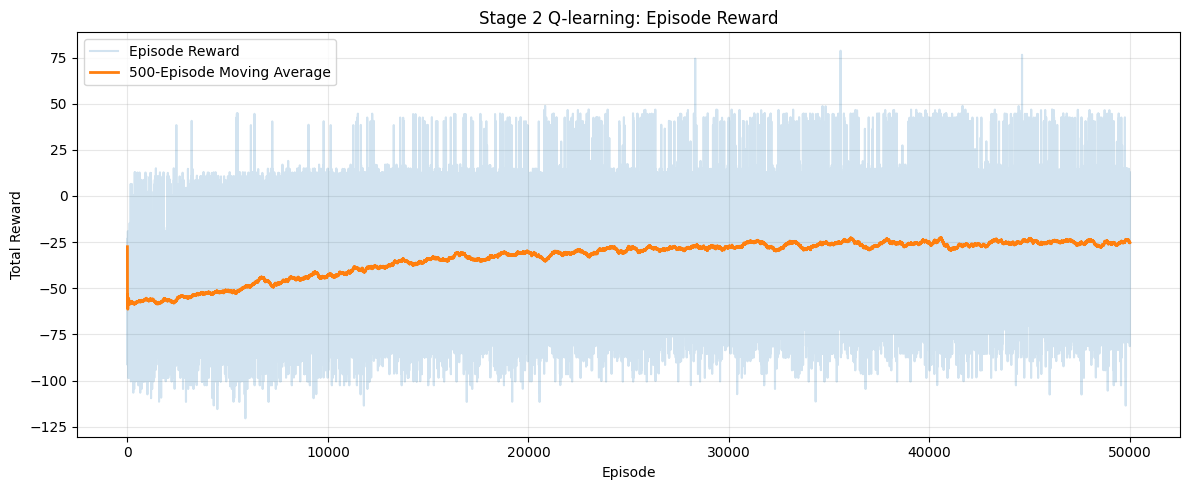

In [ ]:
#===Episode Reward 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['reward'], alpha=0.20, label='Episode Reward')
plt.plot(history_df['episode'], history_df['moving_avg_reward'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 2 Q-learning: Episode Reward')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

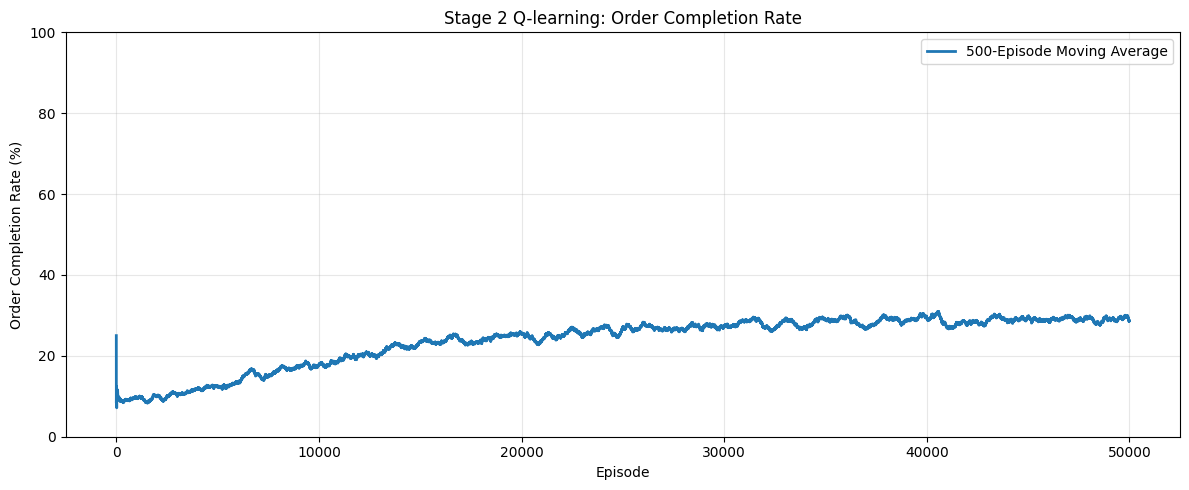

In [ ]:
#===Order Completion Rate 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['moving_avg_completion'], linewidth=2, label=f'{WINDOW}-Episode Moving Average')
plt.title('Stage 2 Q-learning: Order Completion Rate')
plt.xlabel('Episode')
plt.ylabel('Order Completion Rate (%)')
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

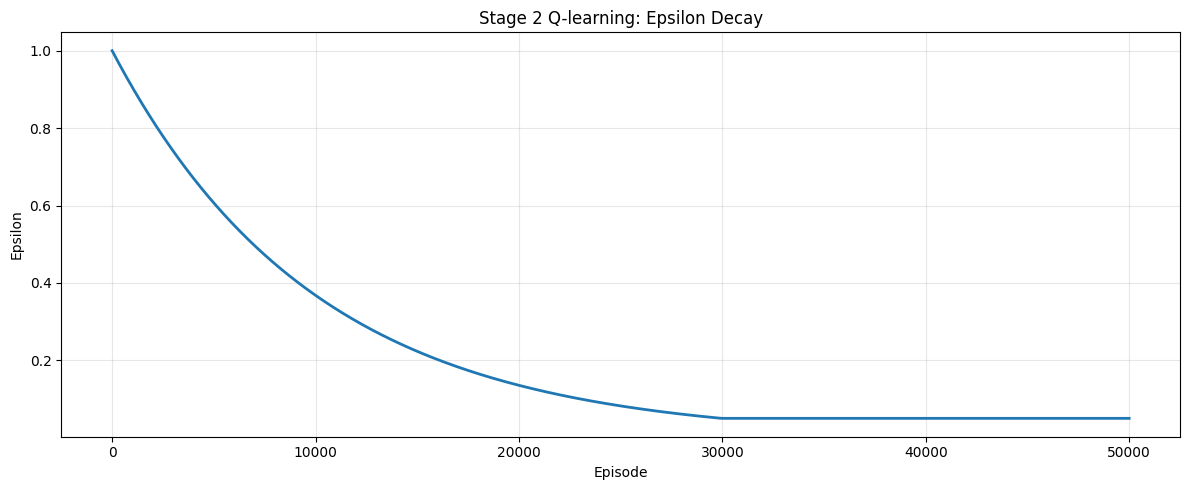

In [ ]:
#===Epsilon Decay 그래프===
plt.figure(figsize=(12, 5))
plt.plot(history_df['episode'], history_df['epsilon'], linewidth=2)
plt.title('Stage 2 Q-learning: Epsilon Decay')
plt.xlabel('Episode')
plt.ylabel('Epsilon')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#===Test Performance 결과 확인===
if PERFORMANCE_PATH.exists():
    performance_df = pd.read_csv(PERFORMANCE_PATH)
    display(performance_df)
else:
    print(f'성능 요약 파일이 없습니다: {PERFORMANCE_PATH}')
    print('학습 기록 그래프는 정상적으로 확인할 수 있습니다.')

,Evaluation Metric,Value
0,Total Evaluation Episodes,"1,000"
1,Average Reward (Return),-22.98
2,Order Completion Rate (%),30.50%
3,Average Served Orders (Max 4),1.22 / 4.0
4,Average Expired Orders,2.78
5,Average Wrong Serves,0.51
6,Average Steps per Episode,13.57


In [ ]:
#===그래프 데이터 저장===
GRAPH_DATA_PATH = RESULT_DIR / 'training_graph_data_stage2.csv'
history_df.to_csv(GRAPH_DATA_PATH, index=False, encoding='utf-8-sig')
print('Graph data saved to:', GRAPH_DATA_PATH)

Graph data saved to: /content/drive/MyDrive/pizza_rl_pj/results_stage2/training_graph_data_stage2.csv
